# Breast Cancer Wisconsin: Supervised Classification Project

## Project Overview

**Dataset:** Breast Cancer Wisconsin (Original), UCI Machine Learning Repository (699 samples).

**Goal:** Develop supervised classification models to classify tumors as Benign or Malignant, with Malignant defined as the positive class.

**Project Structure:**
- **Part 1:** Dataset Exploration (Task 1)
- **Part 2:** Data Preprocessing (Task 2)
- **Part 3:** Exploratory Data Analysis (Task 3)
- **Part 4:** Model Implementation (Task 4)
- **Part 5:** Model Evaluation (Task 5)

**How to Run:** Place the dataset ZIP file (with "wisconsin" in its name) next to this notebook or inside the `data/` folder, then select **Run All**.

The preprocessing stage saves the prepared training and testing datasets in the `preprocessed/` folder for use in the upcoming modeling and evaluation tasks.

# Part 1: Dataset Exploration (Task 1)

## 1.1 Loading the Data

In [1]:
import os, glob, zipfile
import pandas as pd
import numpy as np

DATA_FILE = "breast-cancer-wisconsin.data"

cols = ["id", "Clump_Thickness", "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
        "Marginal_Adhesion", "Single_Epithelial_Cell_Size", "Bare_Nuclei",
        "Bland_Chromatin", "Normal_Nucleoli", "Mitoses", "Class"]

def open_data():
    # 1) the extracted data file next to the notebook or inside ./data
    for folder in [".", "data"]:
        path = os.path.join(folder, DATA_FILE)
        if os.path.exists(path):
            return path
    # 2) otherwise any zip with "wisconsin" in its name (next to the notebook or inside ./data)
    zips = [f for folder in [".", "data"] for f in glob.glob(os.path.join(folder, "*.zip"))
            if "wisconsin" in os.path.basename(f).lower()]
    if not zips:
        raise FileNotFoundError(
            "Dataset not found. Put the UCI zip (its name contains 'wisconsin') next to this notebook "
            f"or inside a 'data' folder, then run this cell again. Current folder: {os.getcwd()}")
    z = zipfile.ZipFile(zips[0])
    member = [n for n in z.namelist() if n.endswith(DATA_FILE)][0]
    return z.open(member)

# The file has no header, and missing values are marked with "?"
df = pd.read_csv(open_data(), header=None, names=cols, na_values="?")
df.head()

,id,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,2
1,1002945,5,4,4,5,7,10.0,3,2,1,2
2,1015425,3,1,1,1,2,2.0,3,1,1,2
3,1016277,6,8,8,1,3,4.0,3,7,1,2
4,1017023,4,1,1,3,2,1.0,3,1,1,2


**Interpretation:** The raw file has no header row, so we added the column names based on `breast-cancer-wisconsin.names`.
Missing values are marked with `?` in the file, and `na_values="?"` converts them to `NaN`.

## 1.2 Structure, Dimensions, and Data Types

In [2]:
print("Shape:", df.shape)
print()
df.info()

Shape: (699, 11)

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           699 non-null    int64  
 1   Clump_Thickness              699 non-null    int64  
 2   Uniformity_Cell_Size         699 non-null    int64  
 3   Uniformity_Cell_Shape        699 non-null    int64  
 4   Marginal_Adhesion            699 non-null    int64  
 5   Single_Epithelial_Cell_Size  699 non-null    int64  
 6   Bare_Nuclei                  683 non-null    float64
 7   Bland_Chromatin              699 non-null    int64  
 8   Normal_Nucleoli              699 non-null    int64  
 9   Mitoses                      699 non-null    int64  
 10  Class                        699 non-null    int64  
dtypes: float64(1), int64(10)
memory usage: 60.2 KB


In [3]:
df.dtypes.value_counts()

int64      10
float64     1
Name: count, dtype: int64

**Interpretation:** The dataset has **699 rows and 11 columns**, all numeric.
`Bare_Nuclei` is `float64` (the others are `int64`) because it contains missing values (`NaN`), and it has only 683 non-null entries.

## 1.3 Target Variable and Predictive Features

In [4]:
target = "Class"
drop_cols = ["id"]
features = [c for c in df.columns if c not in [target] + drop_cols]

print("Target:", target)
print("Dropped columns:", drop_cols)
print(f"Number of features: {len(features)}")
for f in features:
    print(" -", f)

Target: Class
Dropped columns: ['id']
Number of features: 9
 - Clump_Thickness
 - Uniformity_Cell_Size
 - Uniformity_Cell_Shape
 - Marginal_Adhesion
 - Single_Epithelial_Cell_Size
 - Bare_Nuclei
 - Bland_Chromatin
 - Normal_Nucleoli
 - Mitoses


**Interpretation:**
- **Target:** `Class` (2 = Benign, 4 = Malignant).
- **Features (9):** all are cell characteristics from cytology examination, scored on an ordinal scale from 1 to 10.
- **`id`** is not predictive: it is only a sample identifier with no relation to the diagnosis, so it will be dropped during preprocessing.

## 1.4 Descriptive Statistics

In [5]:
df[features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Clump_Thickness,699.0,4.42,2.82,1.0,2.0,4.0,6.0,10.0
Uniformity_Cell_Size,699.0,3.13,3.05,1.0,1.0,1.0,5.0,10.0
Uniformity_Cell_Shape,699.0,3.21,2.97,1.0,1.0,1.0,5.0,10.0
Marginal_Adhesion,699.0,2.81,2.86,1.0,1.0,1.0,4.0,10.0
Single_Epithelial_Cell_Size,699.0,3.22,2.21,1.0,2.0,2.0,4.0,10.0
Bare_Nuclei,683.0,3.54,3.64,1.0,1.0,1.0,6.0,10.0
Bland_Chromatin,699.0,3.44,2.44,1.0,2.0,3.0,5.0,10.0
Normal_Nucleoli,699.0,2.87,3.05,1.0,1.0,1.0,4.0,10.0
Mitoses,699.0,1.59,1.72,1.0,1.0,1.0,1.0,10.0


**Interpretation:**
- All features share the same 1 to 10 scale, so their ranges are similar.
- `Mitoses` has the lowest mean. Most of its values are 1 (75th percentile = 1) but it reaches 10, so it is right-skewed and likely has outliers.
- The remaining features have means between roughly 2.8 and 4.4.
- Standardization is still needed for distance-based and gradient-based models (KNN, SVM, ANN).

## 1.5 Missing Values

In [6]:
missing = df.isnull().sum()
print(missing)
print("\nTotal missing values:", missing.sum())
print(f"Rows containing missing values: {df.isnull().any(axis=1).sum()} "
      f"({df.isnull().any(axis=1).mean()*100:.2f}%)")

id                              0
Clump_Thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

Total missing values: 16
Rows containing missing values: 16 (2.29%)


**Interpretation:** There are **16 missing values**, all in a single column, `Bare_Nuclei` (about 2.3% of rows).
They will be handled in preprocessing. The median is a suitable imputation choice since the values are ordinal.

## 1.6 Duplicates

In [7]:
print("Duplicate rows (all columns):", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())

Duplicate rows (all columns): 8
Duplicate IDs: 54


In [8]:
# Fully duplicated rows
df[df.duplicated(keep=False)].sort_values("id")

,id,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
272,320675,3,3,5,2,3,10.0,7,1,1,4
267,320675,3,3,5,2,3,10.0,7,1,1,4
684,466906,1,1,1,1,2,1.0,1,1,1,2
683,466906,1,1,1,1,2,1.0,1,1,1,2
314,704097,1,1,1,1,1,1.0,2,1,1,2
338,704097,1,1,1,1,1,1.0,2,1,1,2
42,1100524,6,10,10,2,8,10.0,7,3,3,4
253,1100524,6,10,10,2,8,10.0,7,3,3,4
62,1116116,9,10,10,1,10,8.0,3,3,1,4
254,1116116,9,10,10,1,10,8.0,3,3,1,4


**Interpretation:**
- There are **8 fully duplicated rows** (all columns are identical, including `id`). They will be removed during preprocessing.
- There are **54 rows with repeated ID values**, but these are not necessarily full-row duplicates.
- Repeated IDs with different measurements are retained because they are not identical records.
- Rows that share the same feature values but have different IDs are also retained, because identical feature combinations can occur naturally.
- Therefore, only fully identical rows are treated as duplicates.

## 1.7 Class Distribution

In [9]:
counts = df[target].value_counts()
percent = (df[target].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({"count": counts, "percent": percent})

,count,percent
Class,,
2,458,65.52
4,241,34.48


**Interpretation:** Benign (2) = **458 samples (65.5%)**, Malignant (4) = **241 samples (34.5%)**.
The dataset is moderately imbalanced, but not severely imbalanced.
We will initially use the original class distribution without oversampling and evaluate the models using metrics such as Recall, Precision, and F1-score.However, we should use `stratify=y` in the train/test split so that the class ratio is preserved in both sets.

# Part 2: Data Preprocessing (Task 2)

The raw data (`df`) comes from Part 1. The preprocessing steps are done in this order:
1. Remove fully duplicated rows (before splitting, so the same row can never land in both train and test).
2. Drop the irrelevant identifier column `id`.
3. Encode the target so that **Malignant = 1 (positive class)** and Benign = 0.
4. Split 80:20 with `stratify`.
5. Impute missing values using the **training** median only.
6. Standardize using the **training** mean and standard deviation only.
7. Verify there is no data leakage, then save the outputs.

> Why split *before* imputing and scaling? The median, mean, and standard deviation are learned from data.
> If they were computed on the full dataset, information from the test set would leak into training.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
df_raw = df.copy()      # untouched copy of the raw data from Part 1
df = df_raw.copy()
print("Raw shape:", df.shape)

Raw shape: (699, 11)


## 2.1 Handling Duplicate Records

In [11]:
n_before = len(df)
n_dup = df.duplicated().sum()
print("Fully duplicated rows:", n_dup)

df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before} | after: {len(df)} | removed: {n_before - len(df)}")

Fully duplicated rows: 8
Rows before: 699 | after: 691 | removed: 8


**Interpretation:** only rows that are identical in **every** column (including `id`) are treated as true duplicates and removed.
Repeated `id` values with different measurements are kept: Repeated IDs with different measurements are retained because they are not identical records. The available data does not establish why these IDs are repeated.
Rows that share the same feature values but have different `id`s are also kept, because all features are limited to the scale 1 to 10, so identical combinations occur naturally.
Removing duplicates **before** the split also prevents an identical row from appearing in both the training and testing sets (a hidden form of leakage).

## 2.2 Removing Irrelevant Features

In [12]:
df = df.drop(columns=["id"])
print("Remaining columns:", list(df.columns))
print("Shape:", df.shape)

Remaining columns: ['Clump_Thickness', 'Uniformity_Cell_Size', 'Uniformity_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class']
Shape: (691, 10)


**Interpretation:** `id` is only a sample identifier. It carries no medical information, and keeping it could let a model memorize identifiers instead of learning patterns. We are left with 9 predictive features and the target `Class`.

## 2.3 Defining Features and Target (Malignant = Positive Class)

In [13]:
target = "Class"
features = [c for c in df.columns if c != target]

X = df[features].copy()
# Original labels: 2 = Benign, 4 = Malignant  ->  0 = Benign, 1 = Malignant (positive class)
y = df[target].map({2: 0, 4: 1})

assert y.notna().all(), "Unexpected label found in Class"
print("X shape:", X.shape, "| y shape:", y.shape)
print("\nEncoded target distribution:")
print(pd.DataFrame({"count": y.value_counts().sort_index(),
                    "percent": (y.value_counts(normalize=True).sort_index() * 100).round(2)})
        .rename(index={0: "0 (Benign)", 1: "1 (Malignant)"}))

X shape: (691, 9) | y shape: (691,)

Encoded target distribution:
               count  percent
Class                        
0 (Benign)       453    65.56
1 (Malignant)    238    34.44


**Interpretation:** the target is encoded as 0/1 with **Malignant = 1**, so scikit-learn metrics (Precision, Recall, F1, ROC-AUC) treat malignant cases as the positive class, as the assignment requires.

## 2.4 Train/Test Split (80:20)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "share (%)": [round(len(X_train) / len(X) * 100, 1), round(len(X_test) / len(X) * 100, 1)],
    "malignant (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["Train", "Test"])
summary

,rows,share (%),malignant (%)
Train,552,79.9,34.42
Test,139,20.1,34.53


**Interpretation:** the data is split 80% / 20%. `stratify=y` keeps the malignant ratio almost identical in both sets, which matters because the classes are moderately imbalanced. `random_state=42` makes the split reproducible for the whole team.

## 2.5 Handling Missing Values (Median Imputation, fitted on Train only)

In [15]:
print("Missing values BEFORE imputation")
print(pd.DataFrame({"train": X_train.isnull().sum(), "test": X_test.isnull().sum()})
        .loc[lambda d: d.sum(axis=1) > 0])

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)                                   # learn medians from TRAIN only

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=features, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=features, index=X_test.index)

print("\nMedian used to fill Bare_Nuclei (from train):",
      imputer.statistics_[features.index("Bare_Nuclei")])
print("Missing values AFTER imputation  -> train:", int(X_train_imp.isnull().sum().sum()),
      "| test:", int(X_test_imp.isnull().sum().sum()))

Missing values BEFORE imputation
             train  test
Bare_Nuclei     14     2

Median used to fill Bare_Nuclei (from train): 1.0
Missing values AFTER imputation  -> train: 0 | test: 0


**Interpretation:** the missing values are all in `Bare_Nuclei`, a feature on an ordinal 1 to 10 scale, so the **median** is a good choice: it always gives a valid score on the scale and is not affected by outliers (the mean would give non-integer values and be pulled by the high scores).
Dropping the rows is not preferred because the dataset is small and every row is valuable.
The median is learned from the training set only and then applied to both sets, so no information from the test set is used.

## 2.6 Standardization (fitted on Train only)

In [16]:
scaler = StandardScaler()
scaler.fit(X_train_imp)                                # learn mean/std from TRAIN only

X_train_scaled = pd.DataFrame(scaler.transform(X_train_imp), columns=features, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_imp),  columns=features, index=X_test.index)

stats = pd.DataFrame({
    "train mean": X_train_scaled.mean().round(3),
    "train std":  X_train_scaled.std(ddof=0).round(3),
    "test mean":  X_test_scaled.mean().round(3),
    "test std":   X_test_scaled.std(ddof=0).round(3),
})
stats

,train mean,train std,test mean,test std
Clump_Thickness,-0.0,1.0,-0.062,1.032
Uniformity_Cell_Size,0.0,1.0,-0.018,0.979
Uniformity_Cell_Shape,-0.0,1.0,-0.039,0.984
Marginal_Adhesion,0.0,1.0,0.064,0.997
Single_Epithelial_Cell_Size,-0.0,1.0,0.074,1.113
Bare_Nuclei,0.0,1.0,0.011,1.012
Bland_Chromatin,-0.0,1.0,0.077,1.124
Normal_Nucleoli,0.0,1.0,-0.093,0.968
Mitoses,0.0,1.0,-0.093,0.821


**Interpretation:** after standardization the **training** features have mean 0 and standard deviation 1 (exactly, because the scaler was fitted on them).
The **testing** features are close to, but not exactly, 0 and 1. This is expected and correct: the test set was transformed with the training statistics, which is what happens with real unseen data.
Standardization is needed for KNN, SVM, and ANN (distance/gradient based). Decision Tree and Random Forest are not affected by feature scale, so the unscaled (but imputed) version is also saved for them.

## 2.7 Data Leakage Checks

In [17]:
# 1) Verify that imputer and scaler were fitted on training data only

assert np.allclose(
    scaler.mean_,
    X_train_imp.mean().values
)

assert np.allclose(
    imputer.statistics_,
    X_train.median().values
)

print("Imputer and scaler statistics match the training data.")

# 4) No missing values left, shapes consistent
assert X_train_scaled.isnull().sum().sum() == 0 and X_test_scaled.isnull().sum().sum() == 0
assert len(X_train_scaled) == len(y_train) and len(X_test_scaled) == len(y_test)
print("All leakage checks passed.")

Imputer and scaler statistics match the training data.
All leakage checks passed.


**Interpretation:** checks 1, 2, and 4 are strict and passed (statistics come from train only, no shared rows, no missing values).
Check 3 is informational: a number of feature+label combinations appear in both sets. This is expected because every feature takes only values 1 to 10 and many patients share identical measurements, so these are different patients (not duplicated rows) and not leakage. Full-row duplicates, including `id`, were already removed in section 2.1.

## 2.8 Summary and Saving the Outputs

In [18]:
report = pd.DataFrame({
    "Step": ["Raw data", "After removing duplicates", "After dropping id", "Train set", "Test set"],
    "Rows": [len(df_raw), len(df), len(df), len(X_train), len(X_test)],
    "Columns": [df_raw.shape[1], df.shape[1] + 1, df.shape[1], X_train.shape[1], X_test.shape[1]],
})
report

,Step,Rows,Columns
0,Raw data,699,11
1,After removing duplicates,691,11
2,After dropping id,691,10
3,Train set,552,9
4,Test set,139,9


In [19]:
import joblib

os.makedirs("preprocessed", exist_ok=True)

# Scaled version -> KNN, SVM, ANN
X_train_scaled.assign(Class=y_train).to_csv("preprocessed/train_scaled.csv", index=False)
X_test_scaled.assign(Class=y_test).to_csv("preprocessed/test_scaled.csv", index=False)

# Imputed but unscaled version -> Decision Tree, Random Forest, and the EDA before/after plots
X_train_imp.assign(Class=y_train).to_csv("preprocessed/train_unscaled.csv", index=False)
X_test_imp.assign(Class=y_test).to_csv("preprocessed/test_unscaled.csv", index=False)

# Fitted transformers, so the same preprocessing can be reused on new data
joblib.dump({"imputer": imputer, "scaler": scaler, "features": features}, "preprocessed/transformers.joblib")

print(sorted(os.listdir("preprocessed")))

['test_scaled.csv', 'test_unscaled.csv', 'train_scaled.csv', 'train_unscaled.csv', 'transformers.joblib']


**Interpretation / hand-over to the team:**
- `train_scaled.csv`, `test_scaled.csv`: standardized data (use for **KNN, SVM, ANN**).
- `train_unscaled.csv`, `test_unscaled.csv`: imputed but not scaled (use for **Decision Tree, Random Forest**, and for the "before standardization" EDA plots).
- `transformers.joblib`: the fitted imputer and scaler.
- In all files, `Class` is **0 = Benign, 1 = Malignant (positive class)**.
- During hyperparameter tuning with cross-validation, use only the **training** files and keep the test files untouched until the final evaluation. If a model is tuned with `GridSearchCV`, it is safest to put the scaler inside a `Pipeline` so it is re-fitted inside each fold.

**Final note:** in the notebook the variables `X_train_scaled`, `X_test_scaled`, `X_train_imp`, `X_test_imp`, `y_train`, `y_test` are ready to use directly if the next steps are written in the same notebook.

---

# Task 2 Completion Summary

**Task 2: Data Preprocessing has been completed successfully.**

The following preprocessing steps were performed:

- Removed fully duplicated rows from the dataset.
- Dropped the unnecessary `id` column.
- Converted the target variable into numerical labels:
  - `0 = Benign`
  - `1 = Malignant`
- Split the dataset into training and testing sets using an 80:20 ratio with stratification.
- Handled missing values using median imputation.
- Applied StandardScaler to standardize the numerical features.
- Saved the preprocessed datasets and fitted transformers for future use.

**Outcome:**

The dataset is now cleaned, prepared, and divided into training and testing sets.

Both scaled and unscaled versions of the data are available for the upcoming machine learning models.

The project is now ready to proceed to **Part 3: Exploratory Data Analysis (EDA)**.

---

# Part 3: Exploratory Data Analysis (Task 3)

Exploratory Data Analysis (EDA) is performed to understand the dataset, explore feature distributions, identify potential outliers, examine relationships between features, and visualize missing values.

This part uses statistical summaries and visualizations to gain insights into the Breast Cancer Wisconsin dataset before applying machine learning classification models.

## 3.1 EDA Setup

In this section, we import the visualization libraries and configure the plotting style used throughout the EDA process.

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_style("whitegrid")

print("EDA environment is ready!")

EDA environment is ready!


## 3.2 Class Distribution

The purpose of this section is to examine the distribution of the target variable (Class) and understand the balance between Benign and Malignant samples.

The target variable is encoded as:
- 0 = Benign
- 1 = Malignant

A count plot is used to visualize the number of samples in each class.

Class Distribution:
Class
2    453
4    238
Name: count, dtype: int64


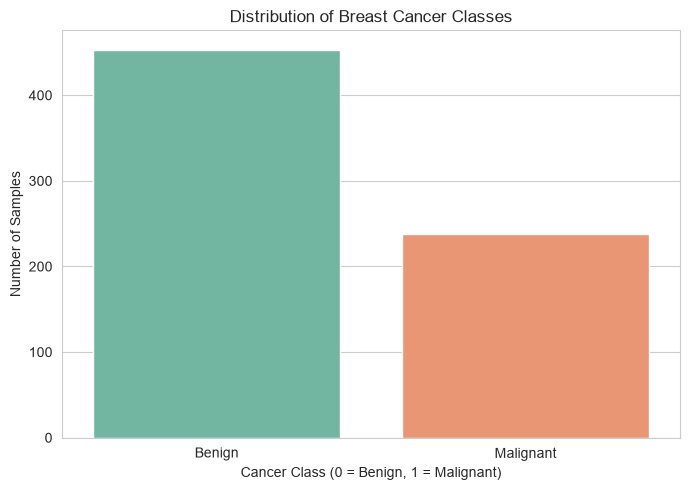

In [21]:
# Calculate the number of samples in each class
class_counts = df["Class"].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x="Class",
    data=df,
    hue="Class",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Cancer Class (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.tight_layout()
plt.show()

### Interpretation

The class distribution shows the number of Benign and Malignant samples in the cleaned dataset.

- Class 0 represents Benign tumors.
- Class 1 represents Malignant tumors.

The distribution helps us understand whether the dataset is balanced or imbalanced. This information is important when evaluating classification models.

## 3.3 Feature Distributions (Histograms)

Histograms are used to examine the distribution of the nine numerical features in the dataset.

They help us understand how feature values are distributed, identify common value ranges, and observe whether the distributions are symmetric or skewed.

Each histogram represents one feature.

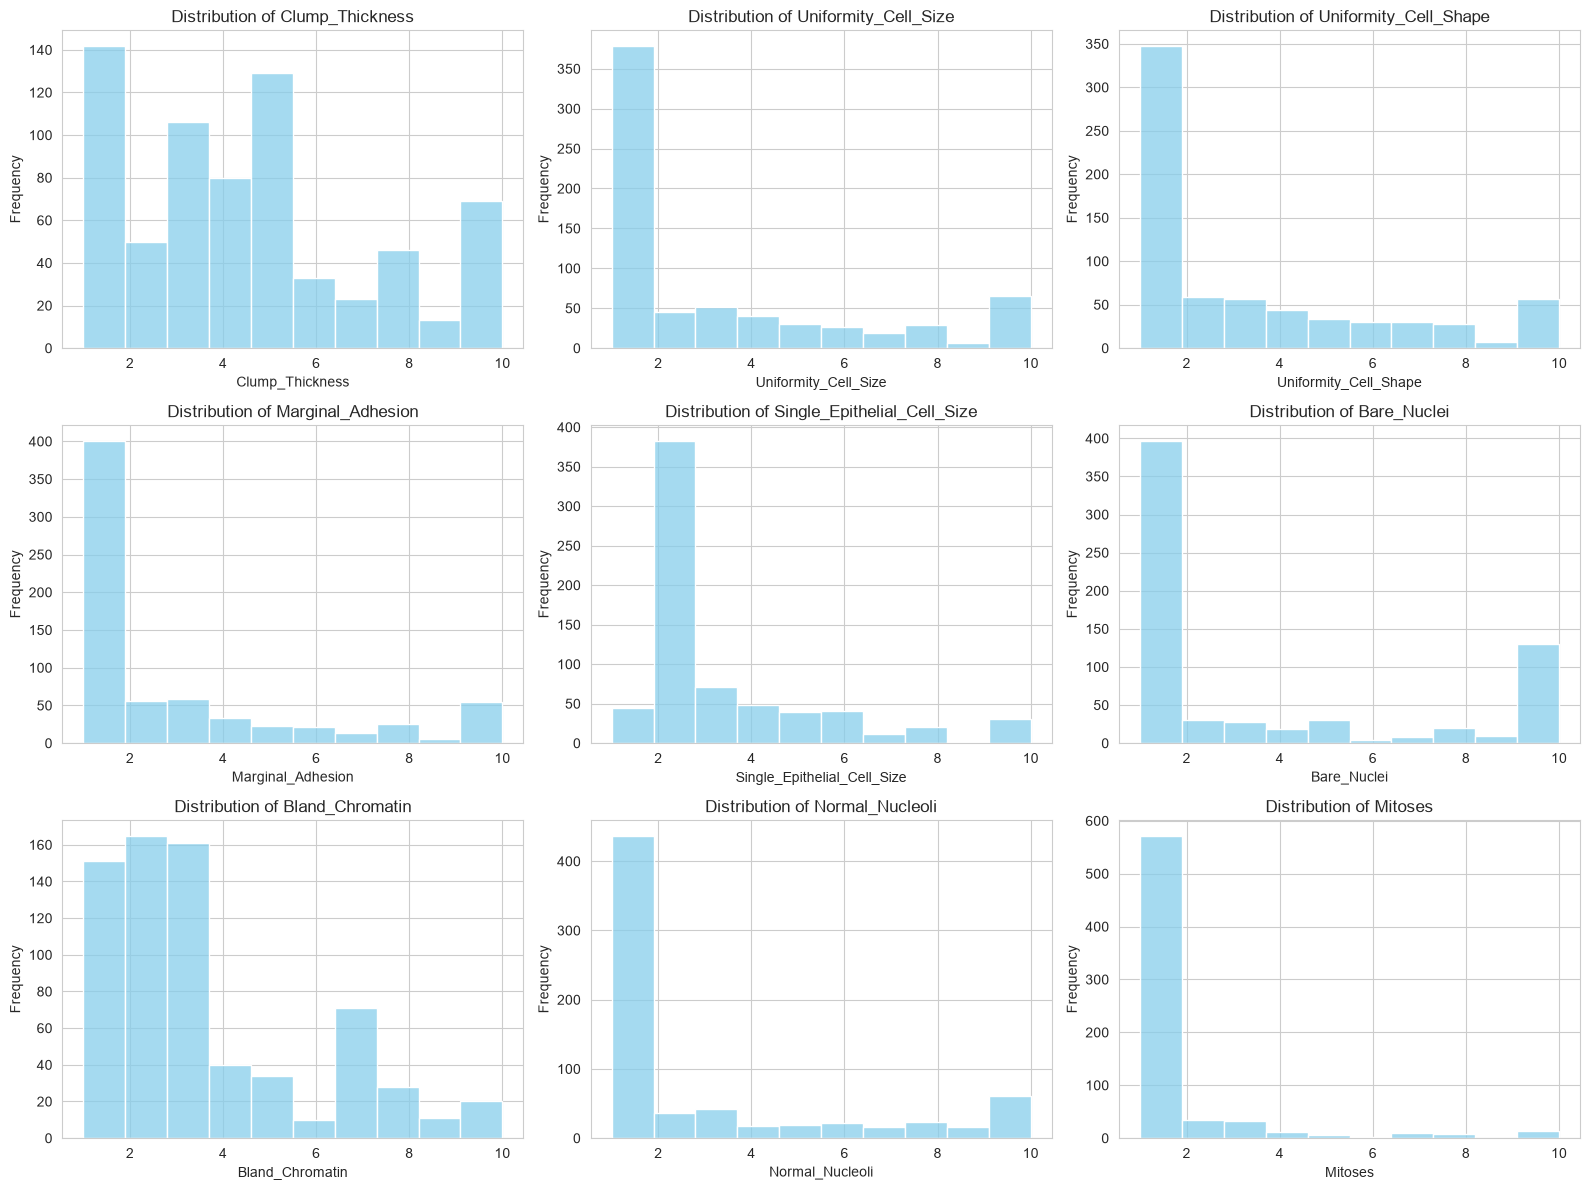

In [22]:
# Histograms of all numerical features

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i, feature in enumerate(features):
    row = i // 3
    col = i % 3

    sns.histplot(
        data=df,
        x=feature,
        bins=10,
        kde=False,
        ax=axes[row, col],
        color="skyblue"
    )

    axes[row, col].set_title(f"Distribution of {feature}")
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation

The histograms show the frequency distribution of the nine numerical features.

They help identify common value ranges and show how feature values are distributed across the dataset.

Some features may have concentrated distributions, while others may show wider or skewed distributions.

## 3.4 Outlier Detection (Boxplots)

Boxplots are used to visualize the spread of numerical features and identify potential outliers.

They display the median, quartiles, and values that fall outside the typical range.

This analysis helps us understand the variability of the features and detect unusual observations.

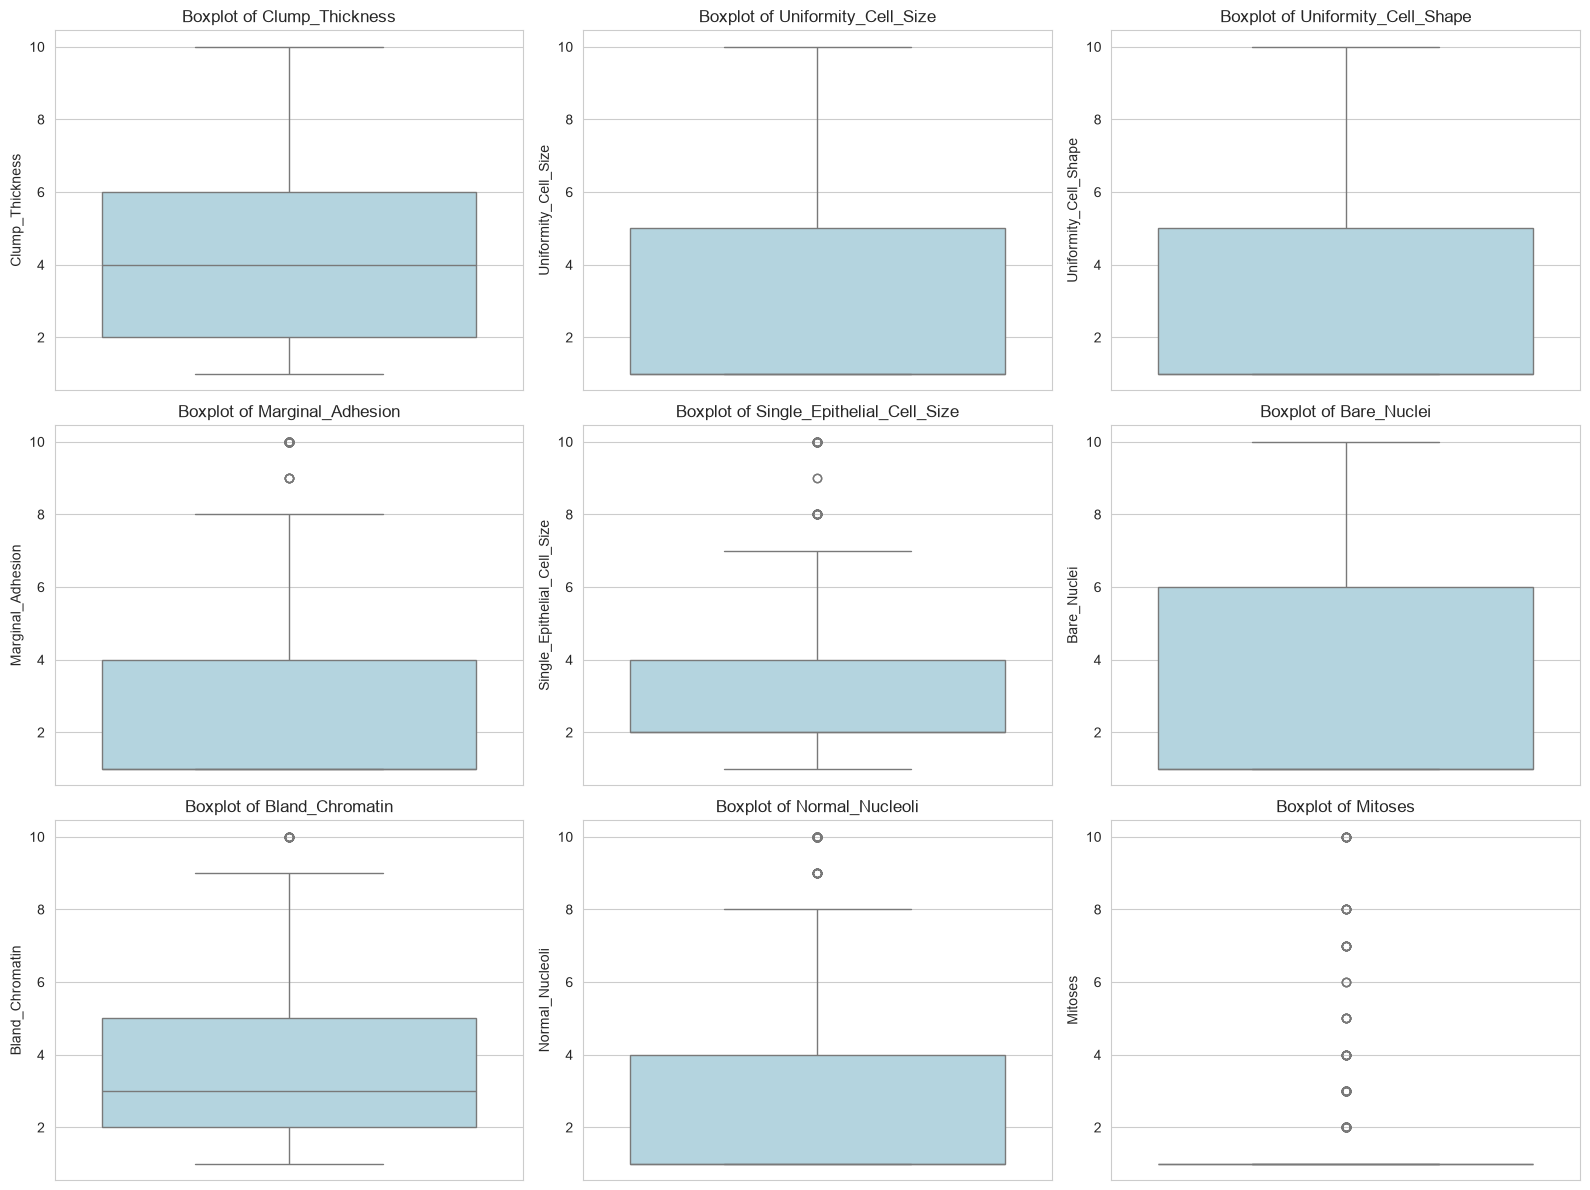

In [23]:
# Boxplots for detecting potential outliers

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i, feature in enumerate(features):
    row = i // 3
    col = i % 3

    sns.boxplot(
        data=df,
        y=feature,
        ax=axes[row, col],
        color="lightblue"
    )

    axes[row, col].set_title(f"Boxplot of {feature}")
    axes[row, col].set_ylabel(feature)

plt.tight_layout()
plt.show()

### Interpretation

The boxplots show the spread and variability of each numerical feature.

- The central line represents the median.
- The box represents the interquartile range (IQR).
- Points outside the whiskers may indicate potential outliers.

These observations help us understand the feature distributions before model implementation.

## 3.5 Feature Correlation (Correlation Heatmap)

A correlation heatmap is used to examine the relationships between numerical features.

Correlation values range from -1 to +1:
- +1 indicates a strong positive correlation.
- -1 indicates a strong negative correlation.
- 0 indicates little or no linear correlation.

This visualization helps identify features that are strongly related to each other.

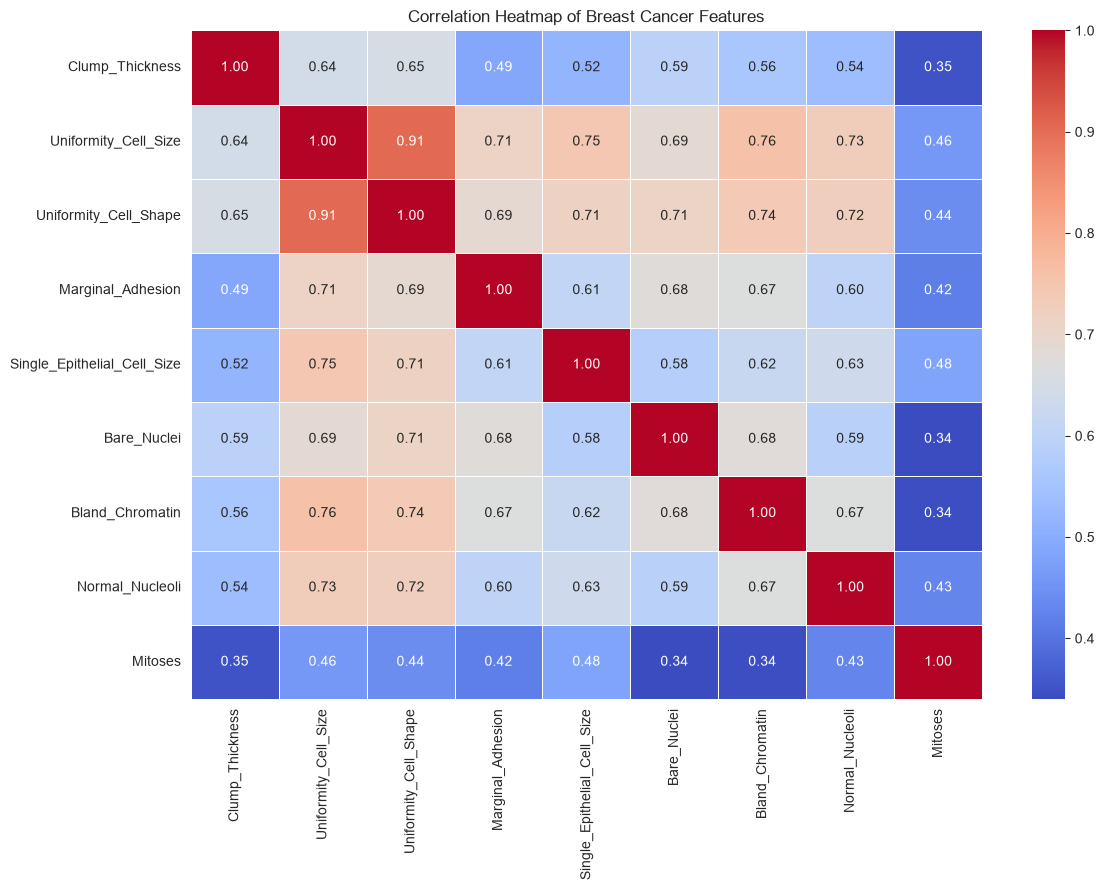

In [24]:
# Correlation Heatmap

plt.figure(figsize=(12, 9))

correlation_matrix = df[features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Breast Cancer Features")
plt.tight_layout()
plt.show()

### Interpretation

The correlation heatmap shows the strength and direction of relationships between numerical features.

- Positive values indicate that two features tend to increase together.
- Negative values indicate an inverse relationship.
- Values close to zero indicate weak linear relationships.

Highly correlated features may contain overlapping information, which can be considered during model development.

## 3.6 Missing Values Visualization

This section visualizes the number of missing values in each numerical feature.

The original dataset contains missing values represented by the symbol "?", which was converted to NaN during data loading.

A bar plot is used to identify which features contain missing values and how many values are missing.

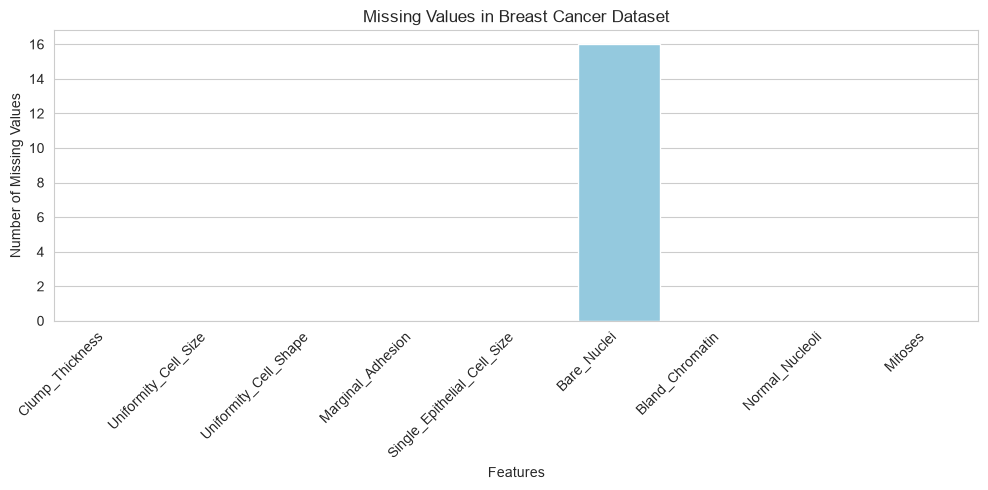

In [25]:
# Missing Values Visualization

missing_values = df_raw[features].isnull().sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_values.index,
    y=missing_values.values,
    color="skyblue"
)

plt.title("Missing Values in Breast Cancer Dataset")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretation

The missing values analysis shows that the Bare_Nuclei feature contains 16 missing values in the original dataset.

The other numerical features do not contain missing values.

These missing values were handled during preprocessing using median imputation fitted on the training data only.

## 3.7 Before and After Standardization

Standardization transforms numerical features so that they have approximately zero mean and unit variance.

In this section, boxplots are used to compare the training features before and after standardization.

The comparison uses:
- X_train_imp: Training data after missing value imputation.
- X_train_scaled: Training data after standardization.

This helps us understand the effect of scaling on feature ranges.

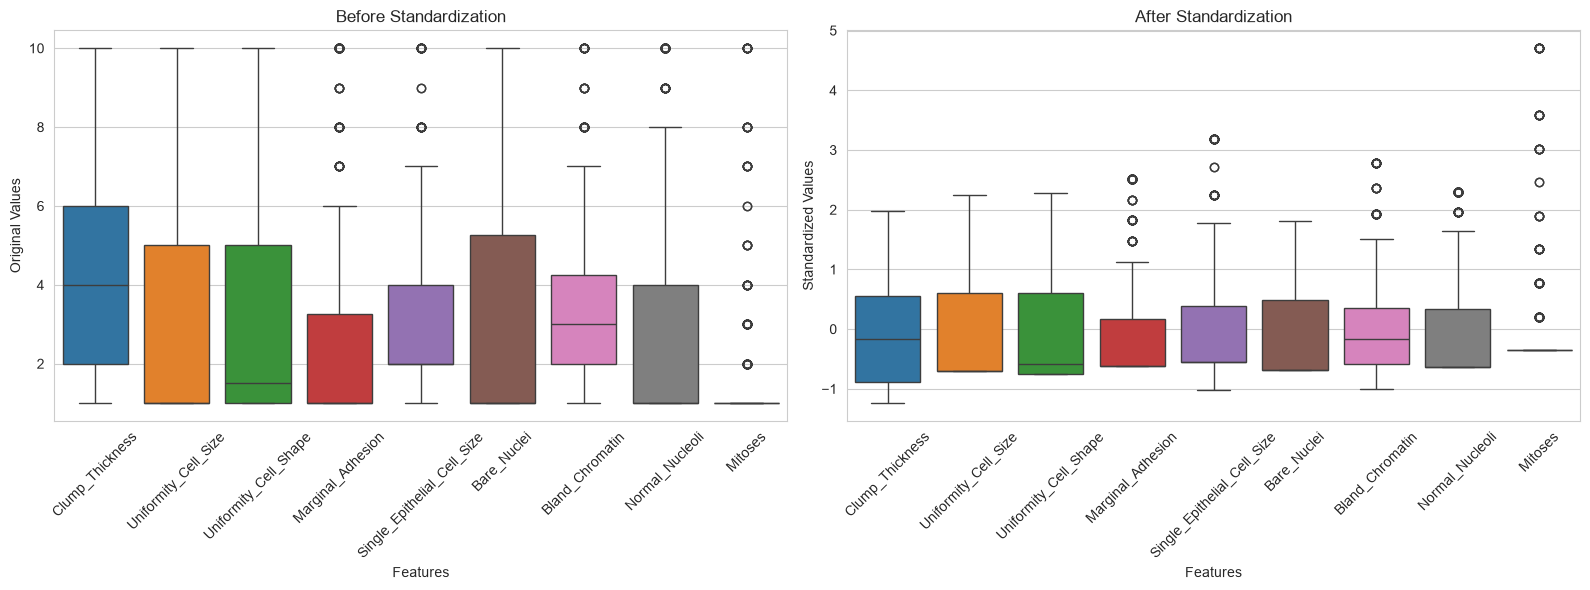

In [26]:
# Before and After Standardization

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Before Standardization
sns.boxplot(
    data=X_train_imp,
    ax=axes[0]
)

axes[0].set_title("Before Standardization")
axes[0].set_xlabel("Features")
axes[0].set_ylabel("Original Values")
axes[0].tick_params(axis="x", rotation=45)

# After Standardization
sns.boxplot(
    data=X_train_scaled,
    ax=axes[1]
)

axes[1].set_title("After Standardization")
axes[1].set_xlabel("Features")
axes[1].set_ylabel("Standardized Values")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Interpretation

Before standardization, the numerical features have different value ranges.

After standardization, the training features are centered around zero and have approximately unit variance.

This transformation is important for distance-based and gradient-based algorithms such as KNN, SVM, and ANN.

## 3.8 EDA Summary and Conclusion

**Task 3: Exploratory Data Analysis (EDA) has been completed successfully.**

The following activities were performed:

- Analyzed the distribution of Benign and Malignant classes.
- Examined the distributions of the nine numerical features using histograms.
- Used boxplots to inspect feature variability and potential outliers.
- Examined relationships between numerical features using a correlation heatmap.
- Visualized missing values in the original dataset.
- Compared the training data before and after standardization.

**Conclusion:**

The EDA process provided useful insights into the dataset, including feature distributions, potential outliers, relationships between features, and missing values.

It also demonstrated the effect of standardization on the training data.

The project is now ready to proceed to **Part 4: Model Implementation**.

---

# Part 4: Model Implementation (Task 4)

In this part we train and tune the five required classifiers with **scikit-learn**:

| # | Algorithm | Scikit-learn class |
|---|-----------|--------------------|
| 1 | K-Nearest Neighbors (KNN) | `KNeighborsClassifier` |
| 2 | Decision Tree (DT) | `DecisionTreeClassifier` |
| 3 | Random Forest (RF) | `RandomForestClassifier` |
| 4 | Artificial Neural Network (ANN) | `MLPClassifier` |
| 5 | Support Vector Machine (SVM) | `SVC` |

**Design decisions:**
- **Malignant = 1 is the positive class**, so Precision, Recall, and F1 are always computed for malignant cases.
- **Hyperparameter tuning uses `GridSearchCV` with 5-fold stratified cross-validation on the training set only.** The test set stays untouched until Part 5.
- **Every model is wrapped in a `Pipeline`** (median imputer, then scaler for KNN/SVM/ANN, then the model) and receives the *raw* `X_train`. This way the imputer and scaler are re-fitted inside each CV fold, so a validation fold never influences the preprocessing (no leakage during tuning), as recommended at the end of Part 2.
- **Scoring:** all five metrics are recorded for every configuration, and the best configuration is selected by **F1-score of the malignant class** (`refit="f1"`). F1 balances missed cancers (Recall) against false alarms (Precision), so it cannot be maximized by simply predicting everything as malignant.

## 4.1 Setup and Cross-Validation Configuration

In [27]:
import time
import joblib
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

# 5-fold stratified CV: every fold keeps the Benign/Malignant ratio
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Malignant = 1 is the positive class, so precision/recall/f1 are computed for Malignant
scoring = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

print("CV folds:", cv.get_n_splits(), "| positive class: 1 (Malignant)")
print("Training set used for tuning:", X_train.shape, "| Test set (untouched):", X_test.shape)

CV folds: 5 | positive class: 1 (Malignant)
Training set used for tuning: (552, 9) | Test set (untouched): (139, 9)


**Interpretation:** `StratifiedKFold` keeps the Benign/Malignant ratio (about 65:35) in every fold, which matters because the classes are moderately imbalanced. `random_state=42` makes the folds identical for every team member.
Tuning is done on **552 training samples**; the **139 test samples** are not used in this part.

## 4.2 Models, Pipelines, and Hyperparameter Grids

In [28]:
def scaled(model):
    """Impute -> standardize -> model (for distance / gradient based models)."""
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("model", model)])

def unscaled(model):
    """Impute -> model (trees do not need scaling)."""
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("model", model)])

models = {
    "KNN": (scaled(KNeighborsClassifier()), {
        "model__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
        "model__weights": ["uniform", "distance"],
        "model__metric": ["euclidean", "manhattan"]}),

    "Decision Tree": (unscaled(DecisionTreeClassifier(random_state=RANDOM_STATE)), {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [3, 4, 5, 6, 8, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]}),

    "Random Forest": (unscaled(RandomForestClassifier(random_state=RANDOM_STATE)), {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
        "model__max_features": ["sqrt", "log2"]}),

    "ANN (MLP)": (scaled(MLPClassifier(max_iter=2000, random_state=RANDOM_STATE)), {
        "model__hidden_layer_sizes": [(8,), (16,), (32,), (16, 8)],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [1e-4, 1e-3, 1e-2],
        "model__learning_rate_init": [0.001, 0.01]}),

    "SVM": (scaled(SVC(random_state=RANDOM_STATE)), [
        {"model__kernel": ["linear"], "model__C": [0.01, 0.1, 1, 10, 100]},
        {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100],
         "model__gamma": ["scale", 0.01, 0.1, 1]}]),
}

from sklearn.model_selection import ParameterGrid
pd.DataFrame({"Hyperparameter combinations": {n: len(ParameterGrid(g)) for n, (_, g) in models.items()}}
             ).assign(**{"Total fits (x5 folds)": lambda d: d.iloc[:, 0] * cv.get_n_splits()})

,Hyperparameter combinations,Total fits (x5 folds)
KNN,28,140
Decision Tree,108,540
Random Forest,72,360
ANN (MLP),48,240
SVM,21,105


**Interpretation:**
- **Pipelines:** KNN, SVM, and ANN are distance/gradient based, so they use `imputer -> StandardScaler -> model`. Decision Tree and Random Forest split on thresholds and are not affected by feature scale, so they use `imputer -> model` only.
- **Search spaces:**
  - **KNN:** number of neighbors (3 to 15), voting weights, and distance metric.
  - **Decision Tree:** split criterion, tree depth, and minimum samples per split/leaf (the main tools to control overfitting).
  - **Random Forest:** number of trees, depth, minimum samples per split/leaf, and features per split.
  - **ANN:** hidden layer architecture, activation function, L2 regularization (`alpha`), and learning rate.
  - **SVM:** a linear kernel with different `C` values, and an RBF kernel with different `C` and `gamma` values (`gamma` has no effect on a linear kernel, so the two kernels use separate grids).
- The whole search is **1,385 model fits** (the table shows 5 folds per combination), which is small enough to run on a normal laptop.

## 4.3 Hyperparameter Tuning with Cross-Validation

In [29]:
# Tune all five models: GridSearchCV on the TRAINING set only
# refit="f1": the final model is the configuration with the best mean CV F1 (Malignant)
searches, tuning_time = {}, {}

for name, (pipe, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit="f1",
                      n_jobs=-1, return_train_score=False)
    gs.fit(X_train, y_train)          # raw X_train: imputer/scaler are re-fitted inside each fold
    searches[name] = gs
    tuning_time[name] = time.time() - t0
    print(f"{name:14s} best CV F1 = {gs.best_score_:.4f}  ({tuning_time[name]:.1f}s)")

KNN            best CV F1 = 0.9555  (2.7s)
Decision Tree  best CV F1 = 0.9297  (9.4s)
Random Forest  best CV F1 = 0.9512  (101.0s)
ANN (MLP)      best CV F1 = 0.9559  (56.5s)
SVM            best CV F1 = 0.9503  (2.3s)


**Interpretation:** every model was tuned on the training folds only. The best mean CV F1-scores are very close for **ANN (0.956), KNN (0.956), RF (0.951), and SVM (0.950)**, while the **Decision Tree is clearly lower (0.930)**. Random Forest and ANN were the slowest to tune because they train many trees / many neural networks.

## 4.4 Best Hyperparameters

In [30]:
best_params = pd.DataFrame({
    name: {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    for name, gs in searches.items()}).T.fillna("-")
best_params

,metric,n_neighbors,weights,criterion,max_depth,min_samples_leaf,min_samples_split,max_features,n_estimators,activation,alpha,hidden_layer_sizes,learning_rate_init,C,kernel
KNN,euclidean,7,uniform,-,-,-,-,-,-,-,-,-,-,-,-
Decision Tree,-,-,-,gini,4,2,2,-,-,-,-,-,-,-,-
Random Forest,-,-,-,-,-,2,2,sqrt,300,-,-,-,-,-,-
ANN (MLP),-,-,-,-,-,-,-,-,-,relu,0.0001,"(8,)",0.001,-,-
SVM,-,-,-,-,-,-,-,-,-,-,-,-,-,0.1,linear


**Interpretation:** (`-` means the hyperparameter does not belong to that model)
- **KNN:** 7 neighbors with Euclidean distance. A moderate `k` smooths out noisy neighbors without blurring the class boundary (uniform and distance weighting tied, and scikit-learn keeps the first one found).
- **Decision Tree:** Gini criterion with `max_depth=4`. A shallow tree was preferred, which shows that deeper trees overfit this small dataset.
- **Random Forest:** 300 trees with `min_samples_leaf=2` and `sqrt` features per split. More trees give a more stable vote.
- **ANN:** a single hidden layer of **8 neurons** with ReLU and a learning rate of 0.001. A very small network was enough, and the different `alpha` values gave the same score (a tie).
- **SVM:** a **linear kernel with a small `C=0.1`** (strong regularization). A linear boundary was as good as the RBF kernel, which suggests the two classes are almost linearly separable in the standardized feature space.

## 4.5 Cross-Validation Performance of the Best Configurations

In [31]:
def cv_row(gs):
    i = gs.best_index_
    r = gs.cv_results_
    return {m: f"{r[f'mean_test_{m}'][i]:.4f} \u00b1 {r[f'std_test_{m}'][i]:.4f}" for m in scoring}

cv_table = pd.DataFrame({name: cv_row(gs) for name, gs in searches.items()}).T
cv_table.columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
cv_table

,Accuracy,Precision,Recall,F1-score,ROC-AUC
KNN,0.9692 ± 0.0092,0.9485 ± 0.0152,0.9632 ± 0.0268,0.9555 ± 0.0137,0.9848 ± 0.0141
Decision Tree,0.9511 ± 0.0109,0.9202 ± 0.0338,0.9421 ± 0.0421,0.9297 ± 0.0160,0.9576 ± 0.0263
Random Forest,0.9656 ± 0.0068,0.9309 ± 0.0267,0.9737 ± 0.0235,0.9512 ± 0.0092,0.9918 ± 0.0033
ANN (MLP),0.9692 ± 0.0092,0.9393 ± 0.0110,0.9737 ± 0.0288,0.9559 ± 0.0139,0.9937 ± 0.0023
SVM,0.9656 ± 0.0089,0.9435 ± 0.0181,0.9579 ± 0.0268,0.9503 ± 0.0130,0.9943 ± 0.0023


**Interpretation:** the table shows the mean ± standard deviation over the 5 validation folds (positive class = Malignant).
- **Recall:** ANN and Random Forest are the highest (0.974), followed by KNN (0.963) and SVM (0.958). The Decision Tree is the lowest (0.942) and also the most variable (± 0.042).
- **Precision:** KNN (0.949) and SVM (0.944) are slightly higher, while the Decision Tree (0.920) is the lowest.
- **ROC-AUC:** SVM, ANN, and RF are all above 0.99. KNN (0.985) and especially the Decision Tree (0.958) are lower, because their scores are coarser (neighbor fractions and leaf proportions).
- The standard deviations (about 0.01 to 0.03) are larger than most of the gaps between the top four models, so these four models are statistically very close.

## 4.6 Top Configurations per Model

In [32]:
# Top 3 configurations per model (ranked by mean CV F1) - shows how sensitive each model is to its hyperparameters
rows = []
for name, gs in searches.items():
    res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_f1").head(3)
    for _, r in res.iterrows():
        rows.append({"Model": name, "Rank": int(r["rank_test_f1"]),
                     "Mean CV F1": round(r["mean_test_f1"], 4),
                     "Mean CV Recall": round(r["mean_test_recall"], 4),
                     "Params": {k.replace("model__", ""): v for k, v in r["params"].items()}})
pd.DataFrame(rows).set_index(["Model", "Rank"])

Mean CV F1  Mean CV Recall                                                                                                           Params
Model         Rank                                                                                                                                             
KNN           1         0.9555          0.9632                                                 {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'distance'}
              1         0.9555          0.9632                                                  {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}
              3         0.9527          0.9579                                                 {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'uniform'}
Decision Tree 1         0.9297          0.9421                             {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2}
              2         0.9277          0.9421                          {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}
              2         0.9277          0.9421                          {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 5}
Random Forest 1         0.9512          0.9737  {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
              1         0.9512          0.9737  {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
              1         0.9512          0.9737    {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
ANN (MLP)     1         0.9559          0.9737                 {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}
              1         0.9559          0.9737                  {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}
              1         0.9559          0.9737                   {'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}
SVM           1         0.9503          0.9579                                                                                   {'C': 0.1, 'kernel': 'linear'}
              2         0.9502          0.9579                                                                        {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
              3         0.9499          0.9526                                                                                     {'C': 1, 'kernel': 'linear'}

**Interpretation:** the ranking shows ties (several configurations obtain exactly the same mean F1).
- KNN, Random Forest, and ANN have **a plateau of equally good settings**: for example, three different `alpha` values for the ANN, or three different depth/feature settings for Random Forest. These models are **not sensitive** to the exact hyperparameters, so the result does not depend on a lucky choice.
- For SVM, the linear kernel (`C=0.1`) and the RBF kernel (`C=10`, `gamma=0.01`) differ by only 0.0001 in F1.
- The Decision Tree is the least stable: its best F1 (0.930) is clearly below the others, and it only works with shallow trees (`max_depth=4`).

## 4.7 Visual Comparison of the CV Results

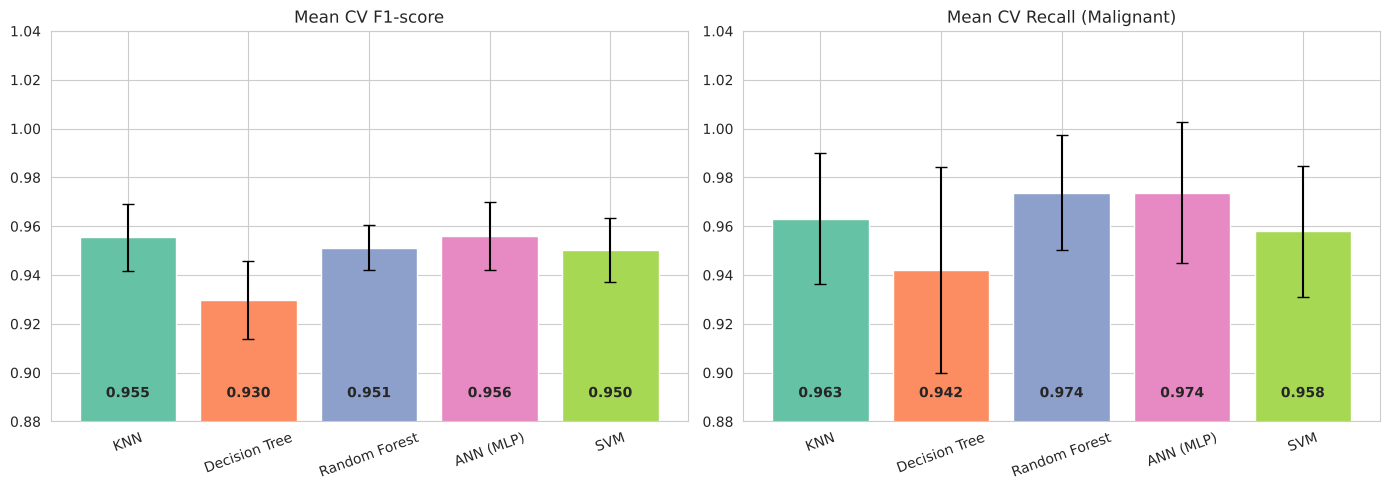

In [33]:
# Visual comparison of the cross-validation results (mean +/- std over 5 folds)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ["f1", "recall"], ["Mean CV F1-score", "Mean CV Recall (Malignant)"]):
    means = [gs.cv_results_[f"mean_test_{metric}"][gs.best_index_] for gs in searches.values()]
    stds  = [gs.cv_results_[f"std_test_{metric}"][gs.best_index_] for gs in searches.values()]
    ax.bar(list(searches), means, yerr=stds, capsize=4, color=sns.color_palette("Set2", len(searches)))
    ax.set_ylim(0.88, 1.04)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    for i, m in enumerate(means):
        ax.text(i, 0.89, f"{m:.3f}", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation:** the error bars (standard deviation across folds) overlap for the four strongest models, in both F1 and Recall. The Decision Tree has the lowest bars and the widest error bar on Recall. This is a first indication that ANN, KNN, SVM, and Random Forest will perform similarly, and the final comparison on the unseen test set is done in Part 5.

## 4.8 Preprocessing Consistency Check and Saving the Models

In [34]:
# Verify the tuned pipelines use exactly the Part 2 preprocessing statistics (no leakage, same transformers)
for name in ["KNN", "SVM", "ANN (MLP)"]:
    est = searches[name].best_estimator_
    assert np.allclose(est.named_steps["imputer"].statistics_, imputer.statistics_)
    assert np.allclose(est.named_steps["scaler"].mean_, scaler.mean_)
    assert np.allclose(est.named_steps["scaler"].scale_, scaler.scale_)
for name in ["Decision Tree", "Random Forest"]:
    assert np.allclose(searches[name].best_estimator_.named_steps["imputer"].statistics_, imputer.statistics_)
print("All tuned pipelines were refitted on the full training set with the same imputer/scaler statistics as Part 2.")

# Save the final tuned models
os.makedirs("models", exist_ok=True)
for name, gs in searches.items():
    fname = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(gs.best_estimator_, f"models/{fname}.joblib")
print(sorted(os.listdir("models")))

All tuned pipelines were refitted on the full training set with the same imputer/scaler statistics as Part 2.
['ann_mlp.joblib', 'decision_tree.joblib', 'knn.joblib', 'random_forest.joblib', 'svm.joblib']


**Interpretation:** after tuning, `GridSearchCV` refits the best pipeline on the **whole training set**. The assertions confirm that the imputer and scaler inside every final pipeline have exactly the same statistics as the ones computed in Part 2 (training data only), so the tuned models and the Part 2 preprocessing are fully consistent and the test set was never used to fit anything.
The five tuned models are saved in the `models/` folder (`.joblib`), so they can be loaded later without retraining.

---

# Task 4 Completion Summary

**Task 4: Model Implementation has been completed successfully.**

- Built five scikit-learn pipelines: **KNN, Decision Tree, Random Forest, ANN (MLP), and SVM**.
- Tuned every model with `GridSearchCV` and **5-fold stratified cross-validation** on the training set only.
- Recorded Accuracy, Precision, Recall, F1-score, and ROC-AUC for every configuration, with **Malignant as the positive class**.
- Selected the best configuration of each model by mean CV F1-score.
- Avoided data leakage by fitting the imputer and scaler inside each CV fold, and verified that the final pipelines match the Part 2 preprocessing.
- Saved the tuned models in `models/`.

**Outcome:** ANN, KNN, SVM, and Random Forest reached very similar CV performance (F1 between 0.950 and 0.956), while the Decision Tree was clearly weaker (F1 = 0.930).

The project is now ready to proceed to **Part 5: Model Evaluation**.

---

# Part 5: Model Evaluation (Task 5)

All five tuned models are now evaluated **once** on the untouched test set (139 samples: **48 malignant** and **91 benign**), with **Malignant as the positive class**.

**Evaluation metrics and what they mean here:**
- **Accuracy:** share of all correct predictions. It can look good even when cancers are missed, because 65% of the samples are benign.
- **Precision:** of the tumors predicted malignant, how many really are malignant, `TP / (TP + FP)`. Low precision means false alarms (unnecessary further tests).
- **Recall (Sensitivity):** of the truly malignant tumors, how many are found, `TP / (TP + FN)`. **This is the most critical metric in this project**, because a false negative is a missed cancer.
- **F1-score:** the harmonic mean of Precision and Recall.
- **ROC-AUC:** how well the model's score separates malignant from benign over all thresholds. It uses predicted probabilities (KNN, DT, RF, ANN) or the decision function (SVM).
- **Confusion Matrix:** the counts of TN, FP, FN, and TP.

**Model selection rule:** models are ranked by **1) Recall**, then **2) F1-score**, then **3) ROC-AUC**, and the result is cross-checked with the cross-validation scores from Part 4 to make sure the choice is not caused by one lucky split.

## 5.1 Test Set Metrics

In [35]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

def get_scores(est, X):
    """Continuous malignancy score used for ROC-AUC (probability, or margin for SVM)."""
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)[:, 1]
    return est.decision_function(X)

results, preds, scores = [], {}, {}
for name, gs in searches.items():
    est = gs.best_estimator_
    y_pred = est.predict(X_test)
    y_score = get_scores(est, X_test)
    preds[name], scores[name] = y_pred, y_score
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall":    recall_score(y_test, y_pred, pos_label=1),
        "F1-score":  f1_score(y_test, y_pred, pos_label=1),
        "ROC-AUC":   roc_auc_score(y_test, y_score),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp})

results_df = pd.DataFrame(results).set_index("Model")
print(f"Test set: {len(y_test)} samples | Malignant (positive): {int(y_test.sum())} | Benign: {int((y_test == 0).sum())}")
results_df.round(4)

Test set: 139 samples | Malignant (positive): 48 | Benign: 91


,Accuracy,Precision,Recall,F1-score,ROC-AUC,TN,FP,FN,TP
Model,,,,,,,,,
KNN,0.9640,0.9778,0.9167,0.9462,0.9823,90,1,4,44
Decision Tree,0.9281,0.8958,0.8958,0.8958,0.9755,86,5,5,43
Random Forest,0.9568,0.9565,0.9167,0.9362,0.9938,89,2,4,44
ANN (MLP),0.9712,0.9583,0.9583,0.9583,0.9961,89,2,2,46
SVM,0.9640,0.9574,0.9375,0.9474,0.9968,89,2,3,45


**Interpretation:**
- **ANN (MLP)** has the best Accuracy (97.1%), Recall (95.8%), and F1-score (95.8%). It missed only **2 of 48** malignant tumors.
- **SVM** has the best ROC-AUC (0.997) and the second-best Recall (93.8%, 3 missed).
- **KNN** has the highest Precision (97.8%, only 1 false alarm) but misses 4 malignant tumors (Recall 91.7%): it is the most "cautious" in calling a tumor malignant.
- **Random Forest** has the same Recall as KNN (91.7%) and a high ROC-AUC (0.994).
- **Decision Tree** is the weakest on every metric (Accuracy 92.8%, F1 = 0.896, 5 missed malignant tumors, 5 false alarms).

## 5.2 Confusion Matrices

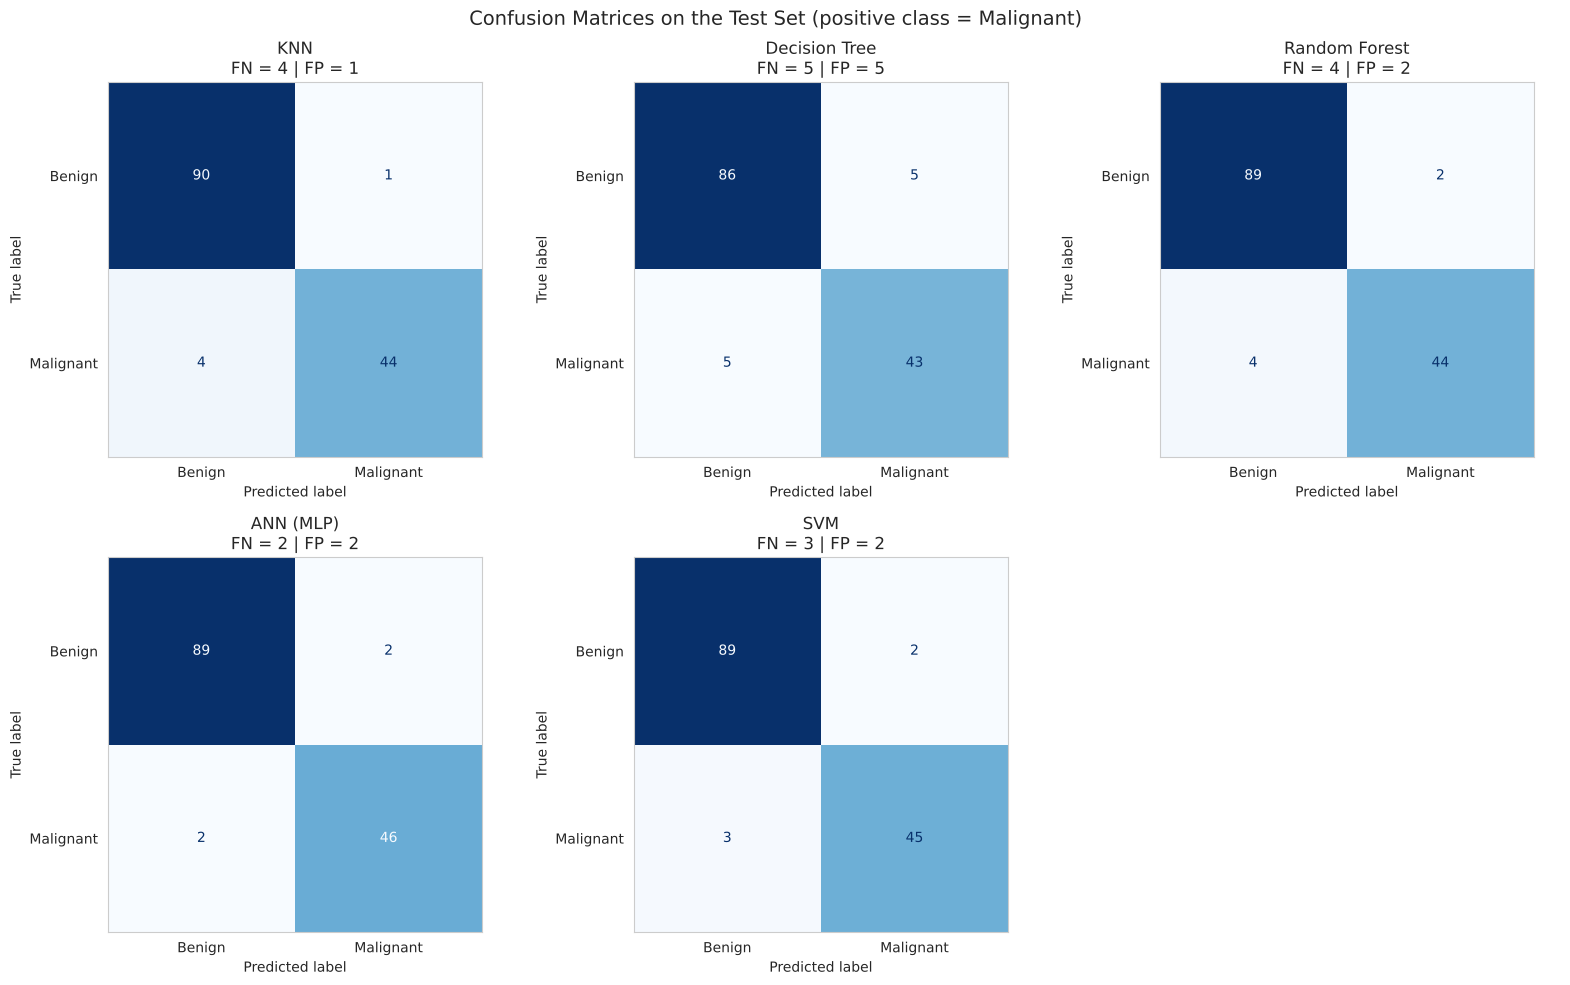

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Benign", "Malignant"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.grid(False)
    r = results_df.loc[name]
    ax.set_title(f"{name}\nFN = {int(r['FN'])} | FP = {int(r['FP'])}")
axes.ravel()[-1].axis("off")
plt.suptitle("Confusion Matrices on the Test Set (positive class = Malignant)", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation:** with Malignant as the positive class, the most serious error is a **False Negative (FN)**: a malignant tumor predicted as benign.
- **False Negatives:** ANN = 2, SVM = 3, KNN = 4, Random Forest = 4, Decision Tree = 5.
- **False Positives:** KNN = 1, ANN = SVM = RF = 2, Decision Tree = 5.
- **Total errors out of 139:** ANN = 4, SVM = 5, KNN = 5, Random Forest = 6, Decision Tree = 10.

ANN makes the fewest mistakes overall and the fewest dangerous ones (FN). The Decision Tree makes the most errors of both types.

## 5.3 ROC Curves

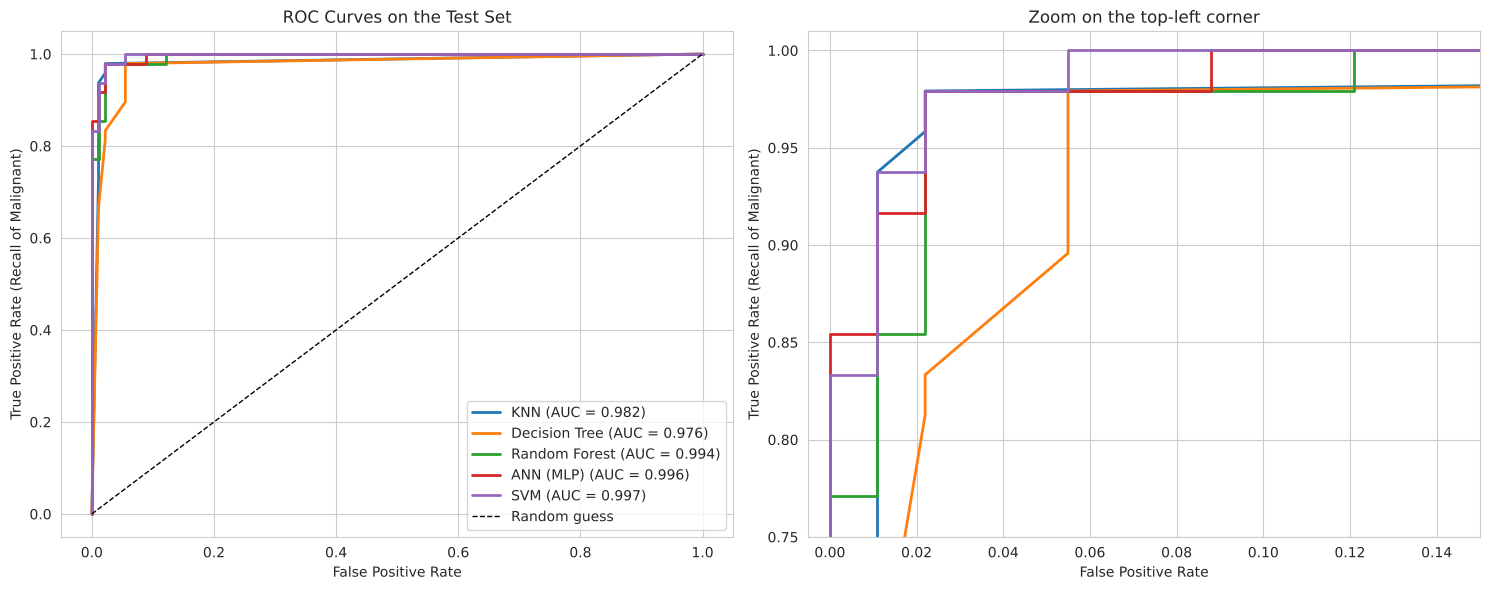

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, zoom in zip(axes, [False, True]):
    for name, y_score in scores.items():
        fpr, tpr, _ = roc_curve(y_test, y_score)
        ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {results_df.loc[name, 'ROC-AUC']:.3f})")
    if not zoom:
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
        ax.set_title("ROC Curves on the Test Set")
        ax.legend(loc="lower right")
    else:
        ax.set_xlim(-0.005, 0.15)
        ax.set_ylim(0.75, 1.01)
        ax.set_title("Zoom on the top-left corner")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate (Recall of Malignant)")
plt.tight_layout()
plt.show()

**Interpretation:** all curves are very close to the top-left corner, which means all models separate the two classes well. The right plot zooms into that corner.
- **SVM (0.997), ANN (0.996), and Random Forest (0.994)** are almost identical and nearly perfect.
- **KNN (0.982)** and the **Decision Tree (0.976)** have lower AUC values. Their scores take only a few distinct values (neighbor fractions and leaf proportions), so their curves only reach 100% Recall at a much higher false positive rate (the lines stay just below 1.0 along the top of the plot).
- ROC-AUC does not depend on a fixed threshold, so it shows that the ANN, SVM, and RF *could* reach even higher Recall with a lower decision threshold, at the cost of more false alarms.

## 5.4 Model Comparison Table and Ranking

In [38]:
comparison = results_df[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "FN", "FP"]].copy()
comparison["CV F1 (train)"] = [searches[n].best_score_ for n in comparison.index]
comparison["F1 gap (CV - test)"] = comparison["CV F1 (train)"] - comparison["F1-score"]

# Rank: 1) Recall (a missed malignant tumor is the costliest error), 2) F1-score, 3) ROC-AUC
comparison = comparison.sort_values(["Recall", "F1-score", "ROC-AUC"], ascending=False)
comparison.insert(0, "Rank", range(1, len(comparison) + 1))
comparison.round(4)

,Rank,Accuracy,Precision,Recall,F1-score,ROC-AUC,FN,FP,CV F1 (train),F1 gap (CV - test)
Model,,,,,,,,,,
ANN (MLP),1,0.9712,0.9583,0.9583,0.9583,0.9961,2,2,0.9559,-0.0024
SVM,2,0.9640,0.9574,0.9375,0.9474,0.9968,3,2,0.9503,0.0029
KNN,3,0.9640,0.9778,0.9167,0.9462,0.9823,4,1,0.9555,0.0093
Random Forest,4,0.9568,0.9565,0.9167,0.9362,0.9938,4,2,0.9512,0.0151
Decision Tree,5,0.9281,0.8958,0.8958,0.8958,0.9755,5,5,0.9297,0.0339


**Interpretation:** the table is ranked by Recall, then F1-score, then ROC-AUC. It also shows **FN** and **FP** counts, and the **F1 gap** between the cross-validation F1 (training data) and the test F1.
- A small gap means the CV estimate was reliable: ANN (-0.002), SVM (0.003), and KNN (0.009) generalize almost exactly as expected.
- Random Forest (0.015) shows slightly more optimism, and the **Decision Tree has the largest gap (0.034)**, which is typical of a less stable model that fits the training folds better than new data.
- No model shows severe overfitting.

## 5.5 Visual Comparison on the Test Set

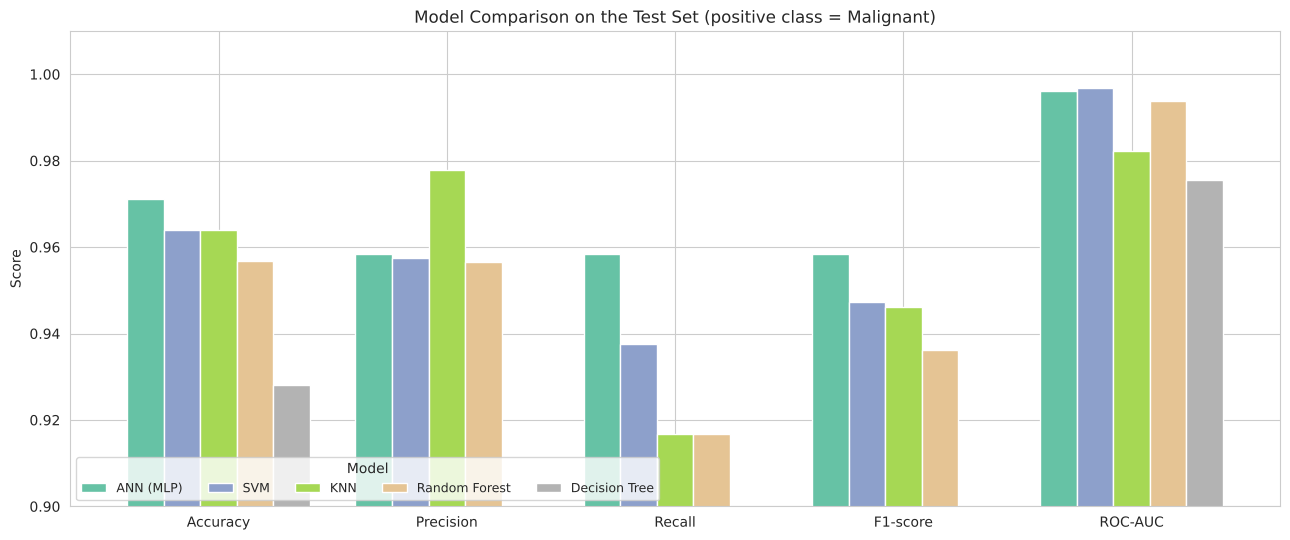

In [39]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_df = comparison[metrics].T

ax = plot_df.plot(kind="bar", figsize=(13, 5.5), width=0.8, colormap="Set2")
ax.set_ylim(0.90, 1.01)
ax.set_ylabel("Score")
ax.set_title("Model Comparison on the Test Set (positive class = Malignant)")
ax.legend(title="Model", loc="lower left", ncol=5, fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:** the grouped bars show that the models are close on Accuracy and ROC-AUC, and that the biggest differences are in **Recall**, where the ANN is the highest and the Decision Tree the lowest.

## 5.6 Best Model Selection

In [40]:
best_name = comparison.index[0]
best_model = searches[best_name].best_estimator_

print(f"Selected model: {best_name}")
print("Best hyperparameters:", {k.replace("model__", ""): v for k, v in searches[best_name].best_params_.items()})
print()
print(classification_report(y_test, preds[best_name], target_names=["Benign", "Malignant"], digits=4))

joblib.dump(best_model, "models/best_model.joblib")

Selected model: ANN (MLP)
Best hyperparameters: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}

              precision    recall  f1-score   support

      Benign     0.9780    0.9780    0.9780        91
   Malignant     0.9583    0.9583    0.9583        48

    accuracy                         0.9712       139
   macro avg     0.9682    0.9682    0.9682       139
weighted avg     0.9712    0.9712    0.9712       139



['models/best_model.joblib']

### Why the ANN (MLP) is selected

1. **Best on the most important metric.** It has the highest test Recall (95.8%): only **2 of 48** malignant tumors were missed, compared with 3 for SVM, 4 for KNN and RF, and 5 for the Decision Tree. It also has the highest F1-score (0.958) and Accuracy (97.1%).
2. **Consistent in cross-validation.** It has the best mean CV F1 (0.956) and ties with Random Forest for the highest CV Recall (0.974). The CV-to-test F1 gap is only -0.002, so the test result is not a lucky split.
3. **Excellent class separation.** Its ROC-AUC (0.996) is practically equal to the best value (SVM, 0.997).
4. **Stable.** The robustness check in 5.7 shows it keeps this performance across different random initializations.

### Important limitations
- The test set has only **48 malignant cases**, so one patient changes Recall by about 2.1 percentage points. The difference between ANN and SVM is **one patient**, and ANN, SVM, and KNN should be considered statistically comparable. The **Decision Tree is the only clearly weaker model**.
- **SVM is a strong, simpler alternative:** it is deterministic, it has the best ROC-AUC, and its linear kernel is easier to explain. If interpretability matters more than the last bit of Recall, SVM is a reasonable choice.
- **KNN** is the best choice only if false alarms are the main concern (highest Precision), but it misses more cancers.
- In a real clinical setting, the decision threshold could be lowered to reduce false negatives even further, and the model should be validated on a larger and independent dataset.

## 5.7 Robustness Check of the Selected ANN

In [41]:
# Robustness check: an ANN depends on its random weight initialization.
# Re-train the selected ANN configuration with 10 different seeds and look at the test-set variation.
ann_params = {k.replace("model__", ""): v for k, v in searches["ANN (MLP)"].best_params_.items()}

rows = []
for seed in range(10):
    pipe = scaled(MLPClassifier(max_iter=2000, random_state=seed, **ann_params))
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_test)
    rows.append({"seed": seed,
                 "Accuracy": accuracy_score(y_test, yp),
                 "Recall": recall_score(y_test, yp),
                 "F1-score": f1_score(y_test, yp),
                 "FN": int(((yp == 0) & (y_test == 1)).sum())})

seed_df = pd.DataFrame(rows).set_index("seed")
seed_df.agg(["mean", "std", "min", "max"]).round(4)

,Accuracy,Recall,F1-score,FN
mean,0.9705,0.9542,0.9571,2.2000
std,0.0023,0.0088,0.0034,0.4216
min,0.9640,0.9375,0.9474,2.0000
max,0.9712,0.9583,0.9583,3.0000


**Interpretation:** a neural network starts from random weights, so we repeated the training of the selected configuration with 10 different seeds. The test Recall stays between **0.938 and 0.958** (mean 0.954, std 0.009), and the number of missed malignant tumors is **2 or 3** in every run. The ANN result is therefore not a product of a lucky seed, and it stays at least as good as the other models.

---

# Task 5 Completion Summary

**Task 5: Model Evaluation has been completed successfully.**

- Evaluated the five tuned models on the unseen test set using **Accuracy, Precision, Recall, F1-score, and ROC-AUC**, with **Malignant as the positive class**.
- Produced a **confusion matrix** for every model and a combined **ROC curve** plot.
- Built a **comparison table** ranked by Recall, F1-score, and ROC-AUC, and compared it with the cross-validation results.
- Selected the **ANN (MLP)** as the best model and documented the reasons and the limitations of the comparison.

**Final results on the test set (139 samples):**

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC | FN | FP |
|-------|----------|-----------|--------|----------|---------|----|----|
| **ANN (MLP)** | **0.9712** | 0.9583 | **0.9583** | **0.9583** | 0.9961 | **2** | 2 |
| SVM | 0.9640 | 0.9574 | 0.9375 | 0.9474 | **0.9968** | 3 | 2 |
| KNN | 0.9640 | **0.9778** | 0.9167 | 0.9462 | 0.9823 | 4 | **1** |
| Random Forest | 0.9568 | 0.9565 | 0.9167 | 0.9362 | 0.9938 | 4 | 2 |
| Decision Tree | 0.9281 | 0.8958 | 0.8958 | 0.8958 | 0.9755 | 5 | 5 |

# Project Conclusion

The project covered the full supervised learning workflow on the Breast Cancer Wisconsin (Original) dataset: exploration, leakage-free preprocessing, EDA, tuning of five classifiers with cross-validation, and evaluation on an untouched test set.
All models except the Decision Tree reached 96% to 97% accuracy and a ROC-AUC above 0.98. The **ANN (MLP)** gave the best balance, with the highest Recall for malignant tumors (95.8%) and only 2 missed cancers, followed closely by **SVM**.
Given the small test set, ANN, SVM, and KNN are close, and further validation on larger data is recommended before any real-world use.